# Wine Quality Predictor

**Department of Computer Applications, Asansol Engineering College**

Guide: Mr. Animesh Ojha

Group members:
- Roshan Shaw (241081010061)
- Rablin Kaur (241081010055)
- Shahzad Gufran (241081010069)
- Sneha Kumari Sharma (241081010076)

---

In this project we use the physical and chemical test results of red wine (acidity, sugar, alcohol etc.) to predict how good the wine is.
We do it in two ways:

1. **Classification** - is the wine *good* (quality 6 or more) or *not good*?
2. **Regression** - what is the exact quality score (a number between 3 and 8)?

We train four models: **KNN, Naive Bayes, Decision Tree and Logistic Regression** (Linear Regression for the score part), compare them, and use the best one in a small web app.

## 1. Importing the libraries

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, mean_squared_error,
                             mean_absolute_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# folders where we keep our pictures, saved models and result tables
for folder in ["images", "models", "results"]:
    os.makedirs(folder, exist_ok=True)

WINE = "#7b1e3a"      # main colour used in the graphs
GREY = "#6b7280"

## 2. Loading the data

The data is the *Wine Quality* dataset from the UCI Machine Learning Repository (Cortez et al., 2009). It has red wines of the Portuguese "Vinho Verde" brand.
The file uses `;` between the values, so we tell pandas that with `sep=";"`.

In [2]:
df = pd.read_csv("data/winequality-red.csv", sep=";")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Understanding the data

Each row is one wine. The first 11 columns are lab measurements (our **features**) and the last column, `quality`, is the score given by wine tasters (our **target**).

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
df.describe().round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000
mean,8.320,0.528,0.271,2.539,0.087,15.875,46.468,0.997,3.311,0.658,10.423,5.636
std,1.741,0.179,0.195,1.410,0.047,10.460,32.895,0.002,0.154,0.170,1.066,0.808
min,4.600,0.120,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400,3.000
25%,7.100,0.390,0.090,1.900,0.070,7.000,22.000,0.996,3.210,0.550,9.500,5.000
50%,7.900,0.520,0.260,2.200,0.079,14.000,38.000,0.997,3.310,0.620,10.200,6.000
75%,9.200,0.640,0.420,2.600,0.090,21.000,62.000,0.998,3.400,0.730,11.100,6.000
max,15.900,1.580,1.000,15.500,0.611,72.000,289.000,1.004,4.010,2.000,14.900,8.000


## 4. Checking for null values and duplicate rows

In [5]:
print("Null values in each column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Null values in each column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 240


There are no null values, so nothing has to be filled. But there are **240 duplicate rows**.
If the same row goes in both the training and the test part, the model gets to "see" the answer, and the score looks better than it really is.
So we remove the duplicates.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print("Rows and columns after removing duplicates:", df.shape)
df.describe().T.round(4).to_csv("results/data_summary.csv")      # saved for the report

Rows and columns after removing duplicates: (1359, 12)


## 5. Quality scores

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


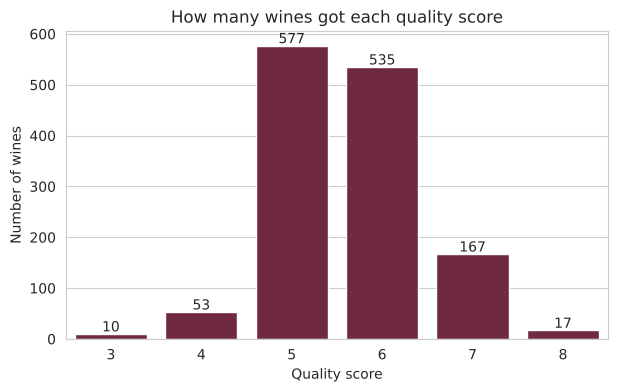

In [7]:
counts = df["quality"].value_counts().sort_index()
print(counts)

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=counts.index, y=counts.values, color=WINE)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.title("How many wines got each quality score")
plt.savefig("images/01_quality_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Most wines are scored 5 or 6. Very few are 3 or 8, so a model will find those hard to predict.

### Making the "good / not good" column
For classification we say a wine is **good (1)** if the quality is 6 or more, and **not good (0)** if it is 5 or less.

good
1    719
0    640
Name: count, dtype: int64

good
1    52.9
0    47.1
Name: proportion, dtype: float64


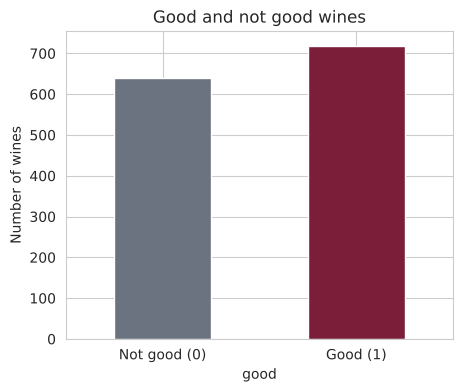

In [8]:
df["good"] = (df["quality"] >= 6).astype(int)
print(df["good"].value_counts())
print()
print((df["good"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(5, 4))
df["good"].value_counts().sort_index().plot(kind="bar", color=[GREY, WINE])
plt.xticks([0, 1], ["Not good (0)", "Good (1)"], rotation=0)
plt.ylabel("Number of wines")
plt.title("Good and not good wines")
plt.savefig("images/02_good_vs_not_good.png", dpi=150, bbox_inches="tight")
plt.show()

The two classes are almost equal (about 53% good and 47% not good), so plain accuracy is a fair measure here.

## 6. Correlation

Correlation tells us how strongly two columns move together. It goes from -1 to +1.

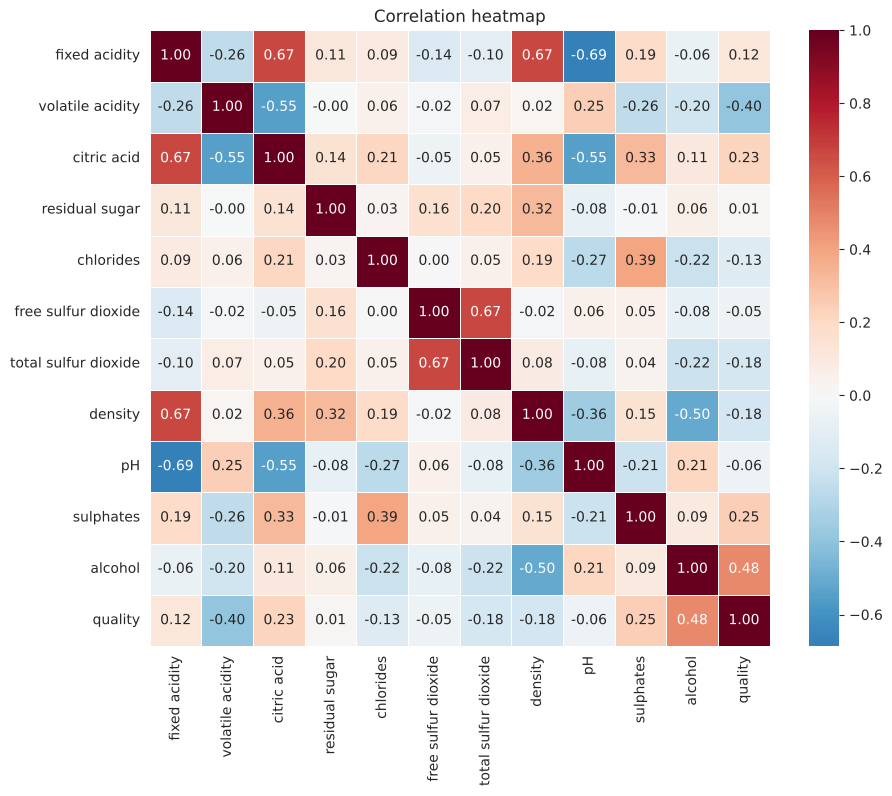

In [9]:
feature_cols = [c for c in df.columns if c not in ["quality", "good"]]

plt.figure(figsize=(10, 8))
sns.heatmap(df[feature_cols + ["quality"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Correlation heatmap")
plt.savefig("images/03_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

volatile acidity       -0.395
density                -0.184
total sulfur dioxide   -0.178
chlorides              -0.131
pH                     -0.055
free sulfur dioxide    -0.050
residual sugar          0.014
fixed acidity           0.119
citric acid             0.228
sulphates               0.249
alcohol                 0.480
dtype: float64


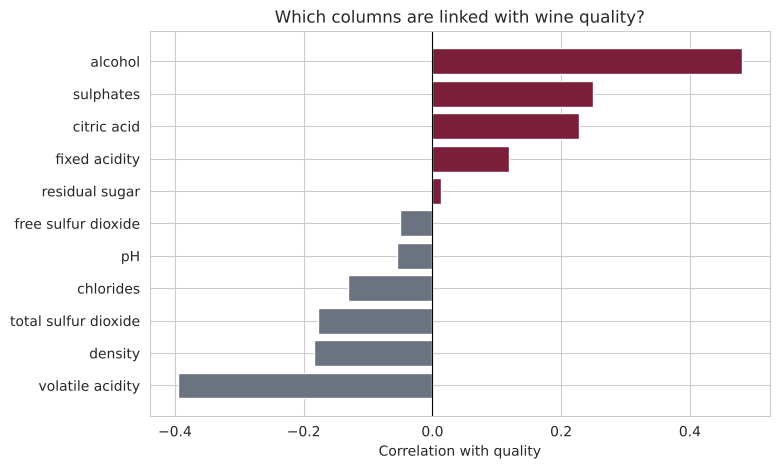

In [10]:
corr_with_quality = df[feature_cols].corrwith(df["quality"]).sort_values()
print(corr_with_quality.round(3))
corr_with_quality.round(4).to_csv("results/correlation_with_quality.csv", header=["correlation"])

plt.figure(figsize=(8, 5))
colors = [WINE if v > 0 else GREY for v in corr_with_quality.values]
plt.barh(corr_with_quality.index, corr_with_quality.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with quality")
plt.title("Which columns are linked with wine quality?")
plt.savefig("images/04_correlation_with_quality.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see:** alcohol (+0.48) has the strongest positive link with quality, and volatile acidity (-0.39) has the strongest negative link.
Sulphates and citric acid also help a little. Wines with more alcohol and less volatile acidity (the vinegar-like part) tend to get higher scores.

## 7. Distribution of the features

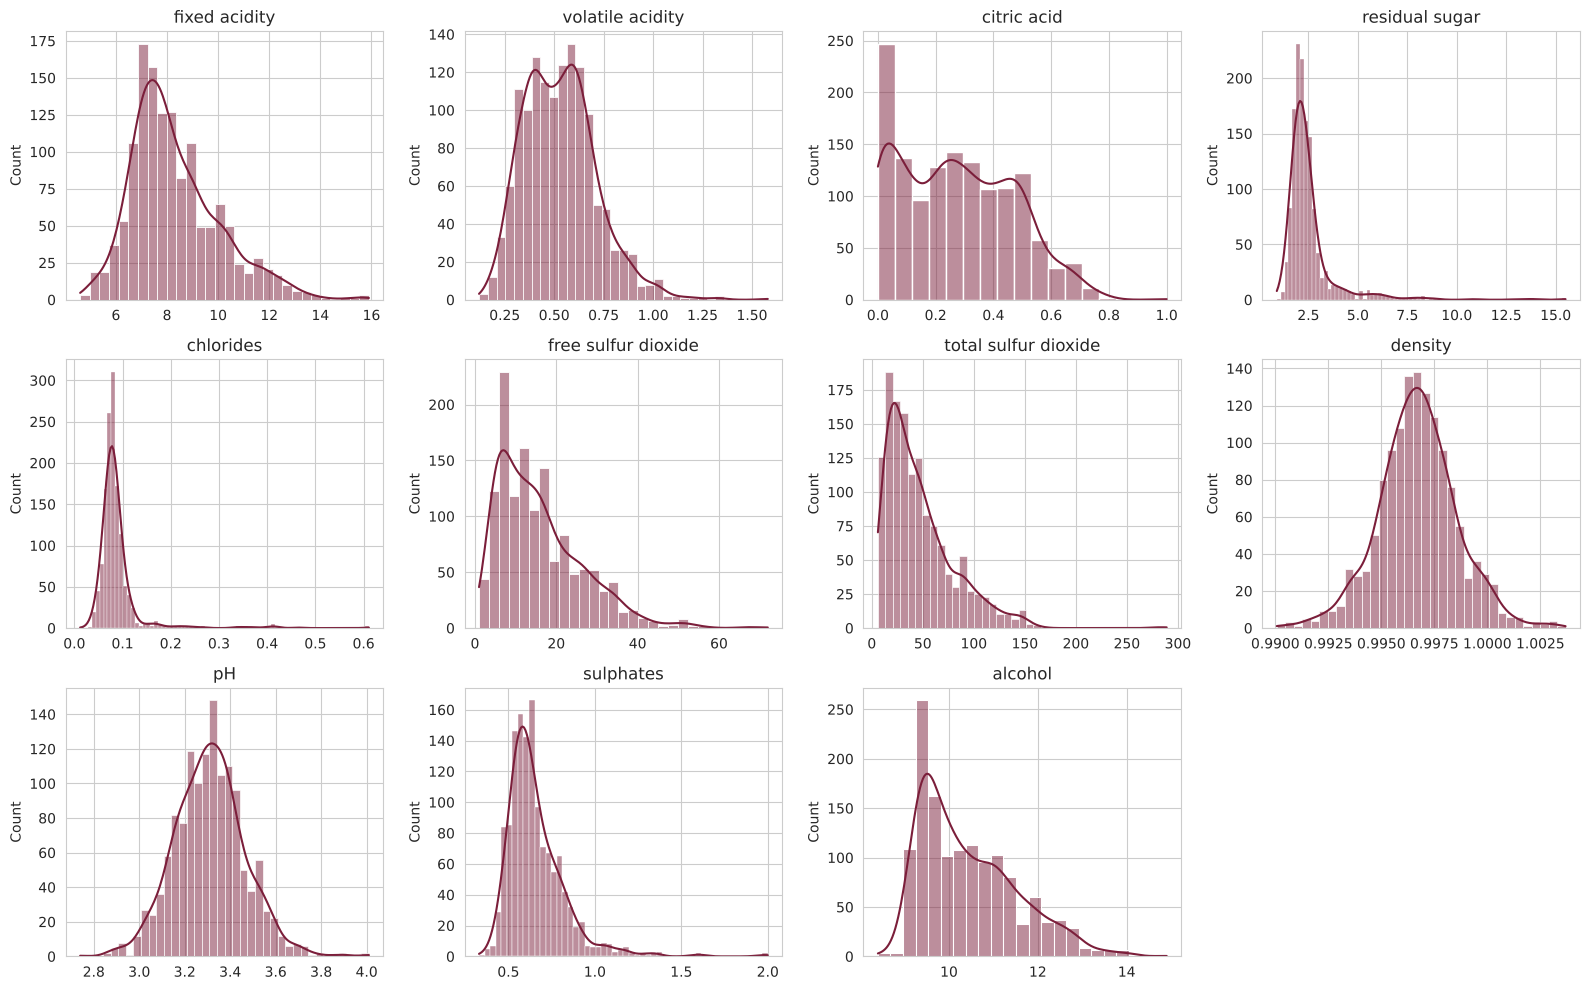

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.histplot(df[col], kde=True, ax=ax, color=WINE)
    ax.set_title(col)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig("images/05_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

Many columns (residual sugar, chlorides, sulphates, total sulfur dioxide) are stretched to the right - a few wines have very large values. These are possible **outliers**.

## 8. Outliers

We use the **IQR method**. The IQR is the gap between the 25% value (Q1) and the 75% value (Q3). Any value below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR` is treated as an outlier.

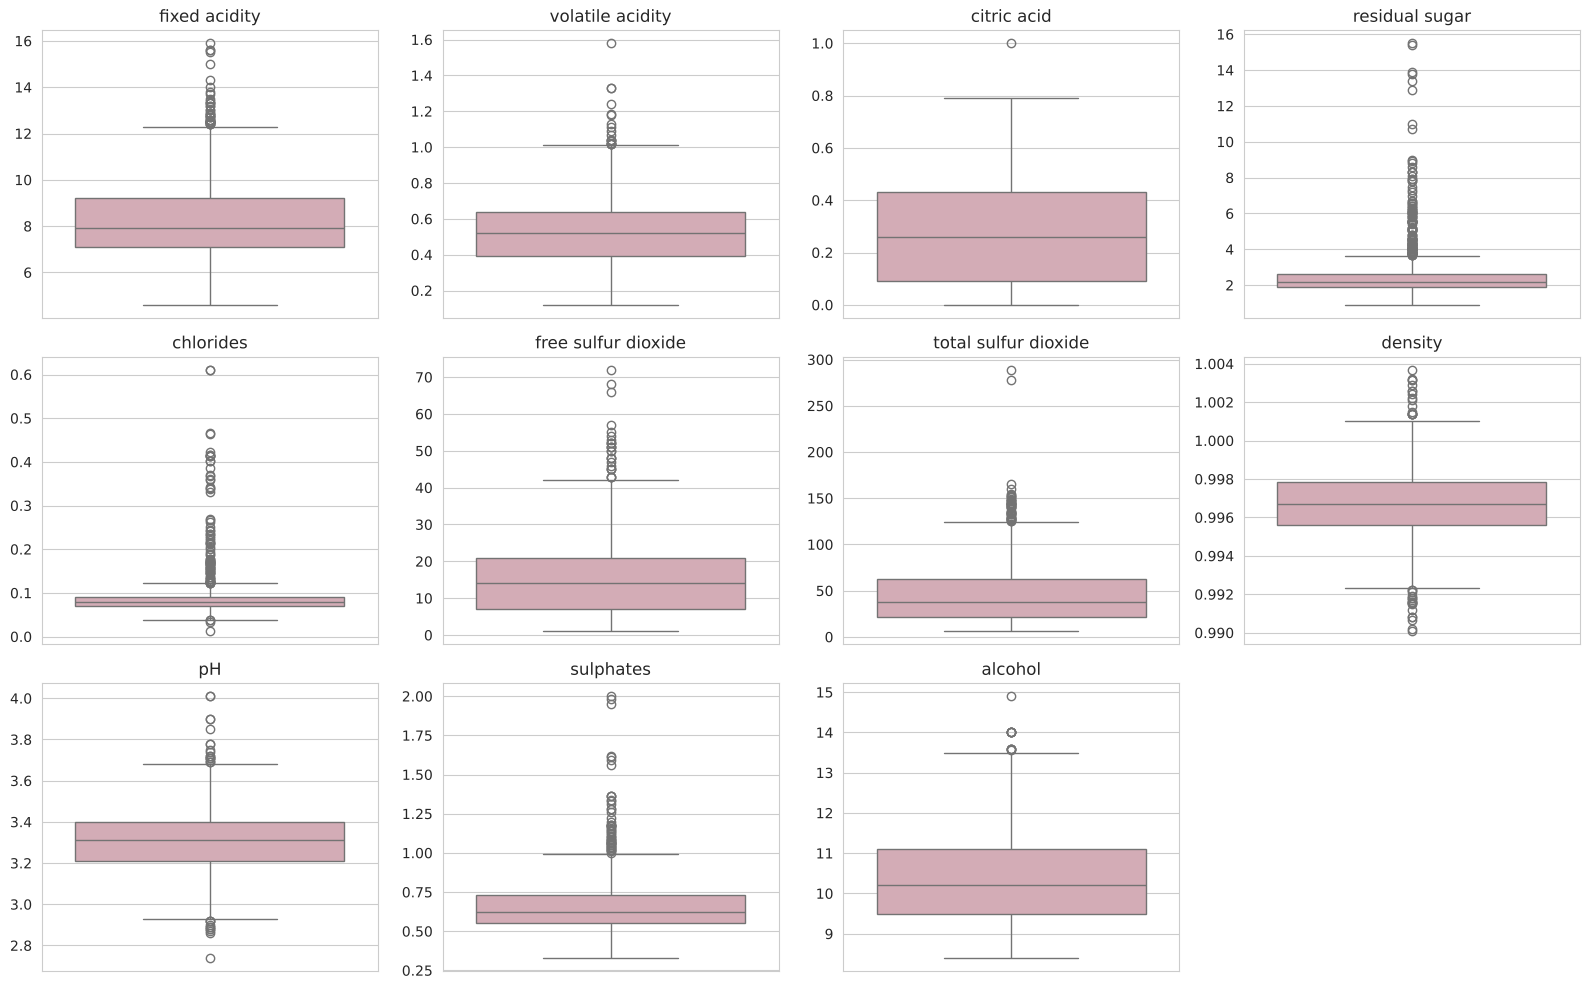

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.boxplot(y=df[col], ax=ax, color="#d9a5b3")
    ax.set_title(col)
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig("images/06_boxplots_before.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
Q1 = df[feature_cols].quantile(0.25)
Q3 = df[feature_cols].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

is_outlier = (df[feature_cols] < lower) | (df[feature_cols] > upper)
outlier_table = pd.DataFrame({
    "outliers": is_outlier.sum(),
    "percent": (is_outlier.mean() * 100).round(1),
    "lower limit": lower.round(4),
    "upper limit": upper.round(4)
}).sort_values("outliers", ascending=False)
outlier_table.to_csv("results/outlier_table.csv")
outlier_table

,outliers,percent,lower limit,upper limit
residual sugar,126,9.3,0.8500,3.6500
chlorides,87,6.4,0.0385,0.1225
sulphates,55,4.0,0.2800,1.0000
total sulfur dioxide,45,3.3,-39.5000,124.5000
fixed acidity,41,3.0,3.9500,12.3500
density,35,2.6,0.9923,1.0012
pH,28,2.1,2.9250,3.6850
free sulfur dioxide,26,1.9,-14.0000,42.0000
volatile acidity,19,1.4,0.0150,1.0150
alcohol,12,0.9,7.1000,13.5000


We do not delete these rows because the dataset is small. Instead we **cap** the values: anything above the upper limit is set equal to the upper limit, and anything below the lower limit is set equal to the lower limit.

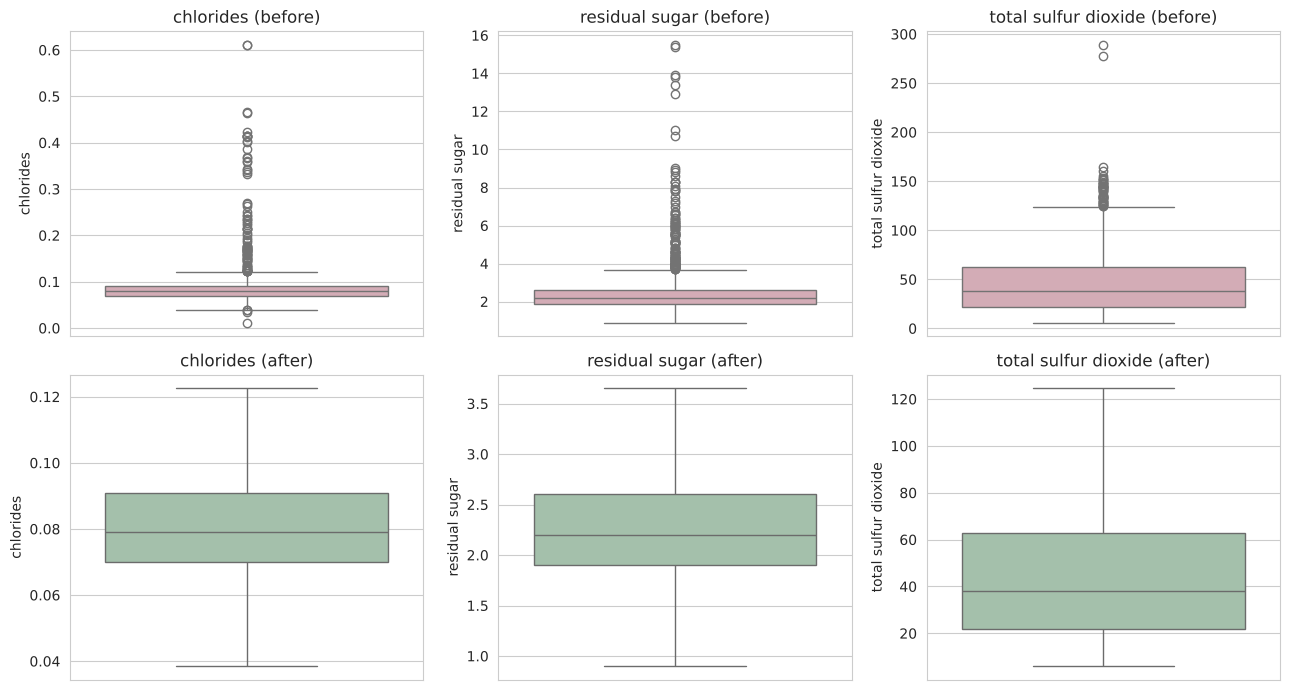

In [14]:
df_clean = df.copy()
df_clean[feature_cols] = df[feature_cols].clip(lower=lower, upper=upper, axis=1)

# comparing 3 columns before and after
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, col in enumerate(["chlorides", "residual sugar", "total sulfur dioxide"]):
    sns.boxplot(y=df[col], ax=axes[0, j], color="#d9a5b3")
    axes[0, j].set_title(col + " (before)")
    sns.boxplot(y=df_clean[col], ax=axes[1, j], color="#9fc5a8")
    axes[1, j].set_title(col + " (after)")
plt.tight_layout()
plt.savefig("images/07_outliers_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Splitting the data into train and test

We keep 75% of the rows for training and 25% for testing, the same ratio as in the sample project.
`stratify` keeps the same good / not good ratio in both parts, and `random_state=42` makes the split the same every time we run.

In [15]:
X = df_clean[feature_cols]
y_class = df_clean["good"]
y_score = df_clean["quality"]

X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y_class, y_score, test_size=0.25, random_state=42, stratify=y_class)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 1019
Testing rows : 340


**About scaling:** KNN and Logistic Regression are affected by the size of the numbers (total sulfur dioxide goes up to ~100 but chlorides are around 0.08).
So for these two we put a `StandardScaler` inside a pipeline. It learns the mean and spread from the training data only and then applies the same change to the test data.
Decision Tree and Naive Bayes do not need it.

# Part A - Classification (good / not good)

## 10. Finding the best settings for KNN and Decision Tree

Best k for KNN: 8


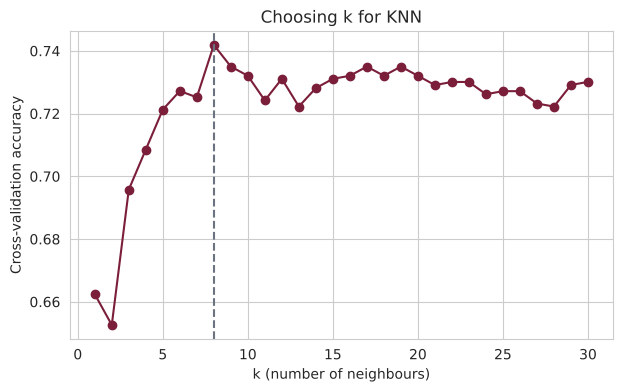

In [16]:
# KNN: which value of k (number of neighbours) is best?
knn_pipe = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())])
knn_search = GridSearchCV(knn_pipe, {"model__n_neighbors": list(range(1, 31))}, cv=5, scoring="accuracy")
knn_search.fit(X_train, y_train)
best_k = knn_search.best_params_["model__n_neighbors"]
print("Best k for KNN:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 31), knn_search.cv_results_["mean_test_score"], marker="o", color=WINE)
plt.axvline(best_k, color=GREY, linestyle="--")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validation accuracy")
plt.title("Choosing k for KNN")
plt.savefig("images/08_knn_best_k.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Decision Tree: how deep should the tree be?
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=42),
                           {"max_depth": list(range(1, 16))}, cv=5, scoring="accuracy")
tree_search.fit(X_train, y_train)
best_depth = tree_search.best_params_["max_depth"]
print("Best max_depth for Decision Tree:", best_depth)

Best max_depth for Decision Tree: 3


If a tree is allowed to grow without any limit it memorises the training data and does badly on new wines (overfitting). Limiting the depth fixes that.

## 11. Training the four classification models

In [18]:
def make_models(k, depth):
    return {
        "KNN": Pipeline([("scaler", StandardScaler()),
                         ("model", KNeighborsClassifier(n_neighbors=k))]),
        "Naive Bayes": GaussianNB(),
        "Decision Tree": DecisionTreeClassifier(max_depth=depth, random_state=42),
        "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                         ("model", LogisticRegression(max_iter=1000))]),
    }

models = make_models(best_k, best_depth)
for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, "trained")

KNN trained
Naive Bayes trained
Decision Tree trained
Logistic Regression trained


## 12. Testing the models

In [19]:
rows = []
predictions = {}
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    cv_acc = cross_val_score(clone(m), X, y_class, cv=5, scoring="accuracy")
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "5-fold CV accuracy": cv_acc.mean(),
    })

clf_results = pd.DataFrame(rows).set_index("Model")
clf_results.round(4).to_csv("results/classification_results.csv")
clf_results.round(4)

,Accuracy,Precision,Recall,F1-score,AUC,5-fold CV accuracy
Model,,,,,,
KNN,0.6912,0.7389,0.6444,0.6884,0.7734,0.7115
Naive Bayes,0.7382,0.8013,0.6722,0.7311,0.8227,0.7196
Decision Tree,0.7206,0.7640,0.6833,0.7214,0.7871,0.6880
Logistic Regression,0.7412,0.7805,0.7111,0.7442,0.8330,0.7270


In [20]:
per_class = []
for name, pred in predictions.items():
    print("=" * 55)
    print(name)
    print(classification_report(y_test, pred, target_names=["Not good (0)", "Good (1)"]))
    rep_dict = classification_report(y_test, pred, output_dict=True)
    for label, cls in [("0", "Not good (0)"), ("1", "Good (1)")]:
        per_class.append({"Model": name, "Class": cls,
                          "Precision": rep_dict[label]["precision"], "Recall": rep_dict[label]["recall"],
                          "F1-score": rep_dict[label]["f1-score"], "Support": int(rep_dict[label]["support"])})
pd.DataFrame(per_class).round(4).to_csv("results/per_class_report.csv", index=False)

KNN
              precision    recall  f1-score   support

Not good (0)       0.65      0.74      0.69       160
    Good (1)       0.74      0.64      0.69       180

    accuracy                           0.69       340
   macro avg       0.69      0.69      0.69       340
weighted avg       0.70      0.69      0.69       340

Naive Bayes
              precision    recall  f1-score   support

Not good (0)       0.69      0.81      0.74       160
    Good (1)       0.80      0.67      0.73       180

    accuracy                           0.74       340
   macro avg       0.74      0.74      0.74       340
weighted avg       0.75      0.74      0.74       340

Decision Tree
              precision    recall  f1-score   support

Not good (0)       0.68      0.76      0.72       160
    Good (1)       0.76      0.68      0.72       180

    accuracy                           0.72       340
   macro avg       0.72      0.72      0.72       340
weighted avg       0.73      0.72      0.72 

### Confusion matrices

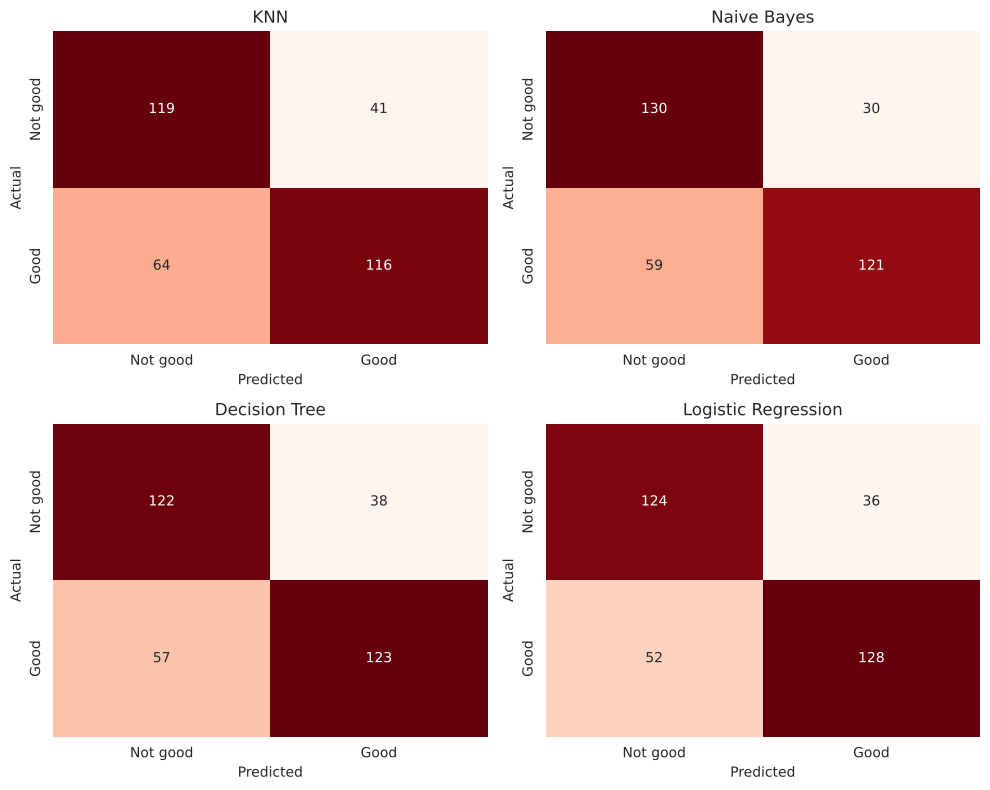

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
cm_rows = []
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", cbar=False, ax=ax,
                xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    cm_rows.append({"Model": name, "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]})
plt.tight_layout()
plt.savefig("images/09_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(cm_rows).to_csv("results/confusion_matrix_values.csv", index=False)

### ROC curves and AUC
The ROC curve shows how the true positive rate and false positive rate change as we move the decision threshold. The closer the curve is to the top-left corner (and the bigger the area under it, AUC), the better.
The dotted diagonal line is a model that guesses randomly (AUC = 0.5).

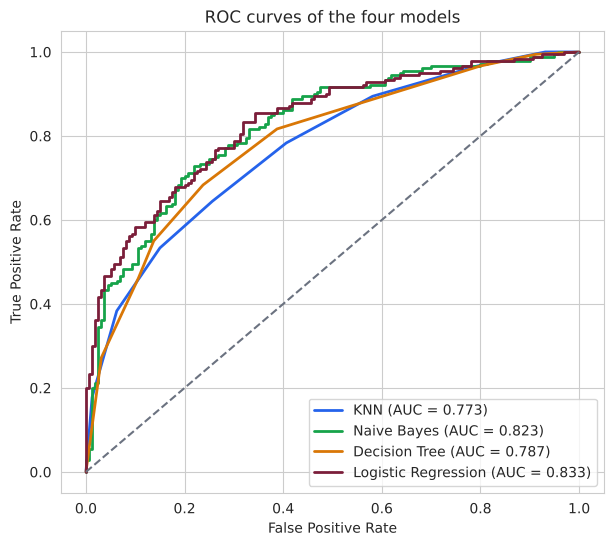

In [22]:
line_colors = {"KNN": "#2563eb", "Naive Bayes": "#16a34a", "Decision Tree": "#d97706", "Logistic Regression": WINE}

plt.figure(figsize=(7, 6))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})",
             color=line_colors[name], linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", color=GREY)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves of the four models")
plt.legend(loc="lower right")
plt.savefig("images/10_roc_all_models.png", dpi=150, bbox_inches="tight")
plt.show()

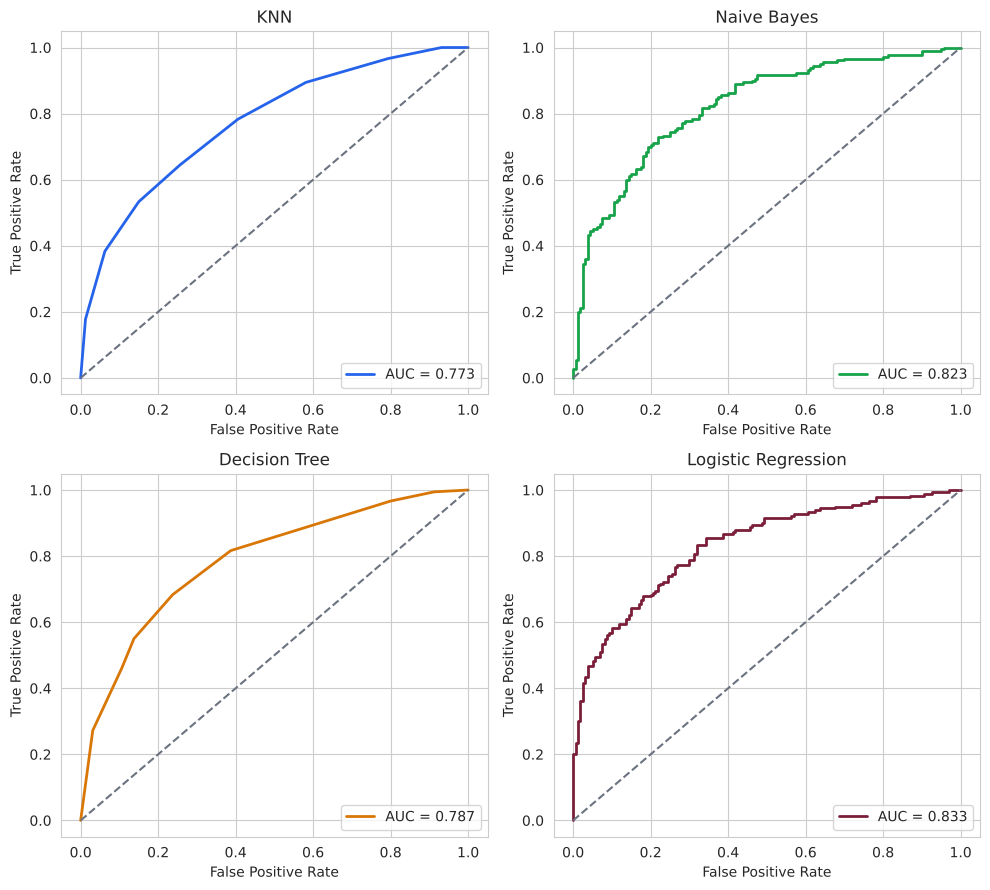

In [23]:
# one ROC picture for each model (used in the report)
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, color=line_colors[name], linewidth=2, label=f"AUC = {roc_auc_score(y_test, prob):.3f}")
    ax.plot([0, 1], [0, 1], linestyle="--", color=GREY)
    ax.set_title(name)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/11_roc_each_model.png", dpi=150, bbox_inches="tight")
plt.show()

### Accuracy comparison

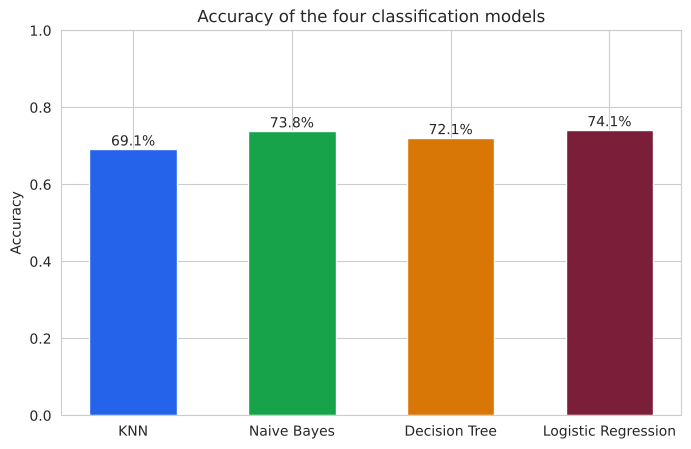

In [24]:
plt.figure(figsize=(8, 5))
acc = clf_results["Accuracy"]
bars = plt.bar(acc.index, acc.values, color=[line_colors[n] for n in acc.index], width=0.55)
for b, v in zip(bars, acc.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v*100:.1f}%", ha="center")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Accuracy of the four classification models")
plt.savefig("images/12_accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Does removing outliers help?

The sample project also trained the models with and without outlier handling. We do the same: same split, same settings, but the first time we use the original values (with outliers).

In [25]:
def accuracy_for(features_df):
    Xtr, Xte, ytr, yte = train_test_split(features_df, y_class, test_size=0.25, random_state=42, stratify=y_class)
    out = {}
    for name, m in make_models(best_k, best_depth).items():
        m.fit(Xtr, ytr)
        out[name] = accuracy_score(yte, m.predict(Xte))
    return out

with_outliers = accuracy_for(df[feature_cols])
without_outliers = accuracy_for(df_clean[feature_cols])

outlier_compare = pd.DataFrame({"With outliers": with_outliers, "Outliers capped": without_outliers})
outlier_compare.round(4).to_csv("results/outlier_comparison.csv")
outlier_compare.round(4)

,With outliers,Outliers capped
KNN,0.7206,0.6912
Naive Bayes,0.7412,0.7382
Decision Tree,0.7206,0.7206
Logistic Regression,0.7529,0.7412


**What we see:** capping did **not** improve the accuracy here. The numbers are close (the test set has 340 wines, so one wine is about 0.3%), and with the original values Logistic Regression is actually 1.2% higher.
We still keep the capped data for the final models, because it keeps the models safe from extreme values - for example someone typing a very large chloride value in the web app. We note this honestly in the report: outlier capping is a safety step and not a big gain for this dataset.

## 14. What did the models learn?

**Decision Tree** - the first few levels of the tree, and which columns it used the most.
**Logistic Regression** - the coefficient of each (scaled) column. A positive number pushes the wine towards "good".

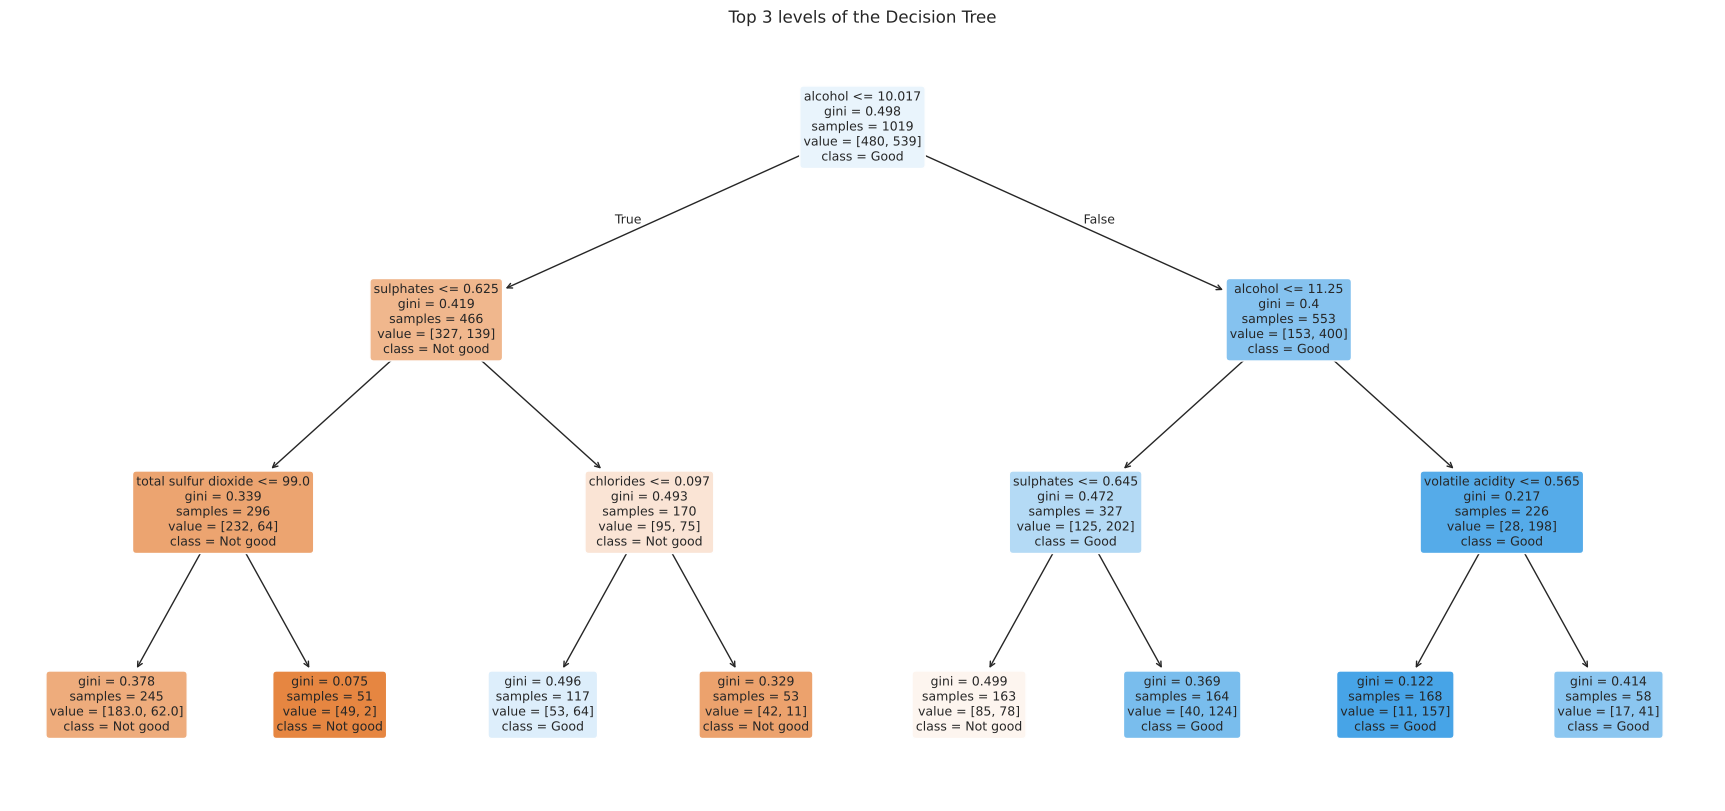

In [26]:
plt.figure(figsize=(22, 10))
plot_tree(models["Decision Tree"], max_depth=3, feature_names=feature_cols,
          class_names=["Not good", "Good"], filled=True, rounded=True, fontsize=9)
plt.title("Top 3 levels of the Decision Tree")
plt.savefig("images/13_decision_tree.png", dpi=130, bbox_inches="tight")
plt.show()

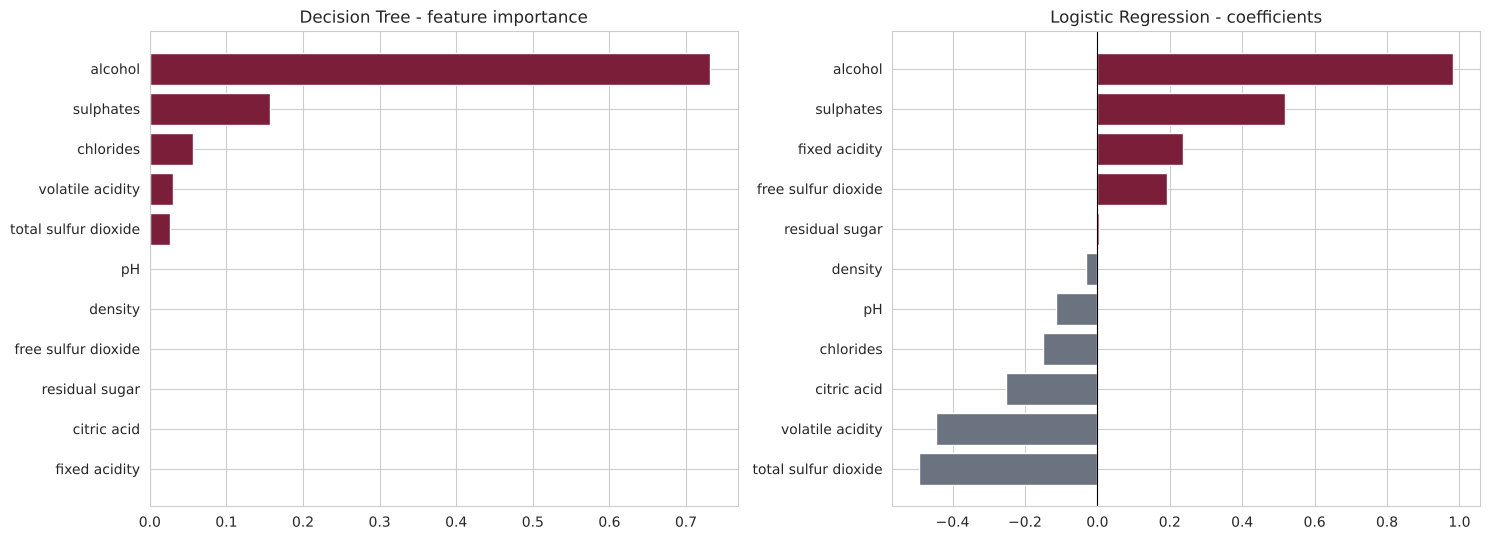

Logistic Regression intercept: 0.2138
alcohol                 0.9830
sulphates               0.5183
fixed acidity           0.2371
free sulfur dioxide     0.1932
residual sugar          0.0053
density                -0.0311
pH                     -0.1155
chlorides              -0.1501
citric acid            -0.2514
volatile acidity       -0.4468
total sulfur dioxide   -0.4926
dtype: float64


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

dt_imp = pd.Series(models["Decision Tree"].feature_importances_, index=feature_cols).sort_values()
axes[0].barh(dt_imp.index, dt_imp.values, color=WINE)
axes[0].set_title("Decision Tree - feature importance")

lr_coef = pd.Series(models["Logistic Regression"].named_steps["model"].coef_[0], index=feature_cols).sort_values()
axes[1].barh(lr_coef.index, lr_coef.values, color=[WINE if v > 0 else GREY for v in lr_coef.values])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Logistic Regression - coefficients")

plt.tight_layout()
plt.savefig("images/14_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

lr_coef.round(4).to_csv("results/lr_coefficients.csv", header=["coefficient"])
dt_imp.round(4).to_csv("results/dt_importance.csv", header=["importance"])

print("Logistic Regression intercept:", round(models["Logistic Regression"].named_steps["model"].intercept_[0], 4))
print(lr_coef.round(4).sort_values(ascending=False))

## 15. Choosing the best classification model

In [28]:
best_clf_name = clf_results.sort_values(["Accuracy", "F1-score", "AUC"], ascending=False).index[0]
print("Best classification model:", best_clf_name)
print("Accuracy:", round(clf_results.loc[best_clf_name, "Accuracy"] * 100, 2), "%")
print("AUC     :", round(clf_results.loc[best_clf_name, "AUC"], 4))

Best classification model: Logistic Regression
Accuracy: 74.12 %
AUC     : 0.833


# Part B - Regression (predicting the quality score)

Now the target is the actual score (3 to 8). We use the regression version of each model:
**KNN Regressor, Decision Tree Regressor and Linear Regression.**
(Naive Bayes is only a classification method, there is no regression version of it, so it is not used here.)

The measures are:
- **RMSE** - average size of the error (lower is better)
- **MAE** - average of the absolute errors (lower is better)
- **R-squared** - how much of the ups and downs of quality the model explains (1 is perfect, 0 is no better than always guessing the average)

In [29]:
# best settings for KNN regressor and Decision Tree regressor
knn_r_search = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor())]),
                            {"model__n_neighbors": list(range(1, 31))}, cv=5, scoring="neg_root_mean_squared_error")
knn_r_search.fit(X_train, s_train)
best_k_reg = knn_r_search.best_params_["model__n_neighbors"]

tree_r_search = GridSearchCV(DecisionTreeRegressor(random_state=42),
                             {"max_depth": list(range(1, 16))}, cv=5, scoring="neg_root_mean_squared_error")
tree_r_search.fit(X_train, s_train)
best_depth_reg = tree_r_search.best_params_["max_depth"]

print("Best k for KNN Regressor:", best_k_reg)
print("Best max_depth for Decision Tree Regressor:", best_depth_reg)

Best k for KNN Regressor: 19
Best max_depth for Decision Tree Regressor: 4


In [30]:
reg_models = {
    "KNN Regressor": Pipeline([("scaler", StandardScaler()),
                               ("model", KNeighborsRegressor(n_neighbors=best_k_reg))]),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=best_depth_reg, random_state=42),
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
}

reg_rows = []
reg_pred = {}
for name, m in reg_models.items():
    m.fit(X_train, s_train)
    p = m.predict(X_test)
    reg_pred[name] = p
    reg_rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(s_test, p)),
        "MAE": mean_absolute_error(s_test, p),
        "R-squared": r2_score(s_test, p),
    })

reg_results = pd.DataFrame(reg_rows).set_index("Model")
reg_results.round(4).to_csv("results/regression_results.csv")
reg_results.round(4)

,RMSE,MAE,R-squared
Model,,,
KNN Regressor,0.7100,0.5540,0.3478
Decision Tree Regressor,0.7194,0.5593,0.3304
Linear Regression,0.6796,0.5222,0.4024


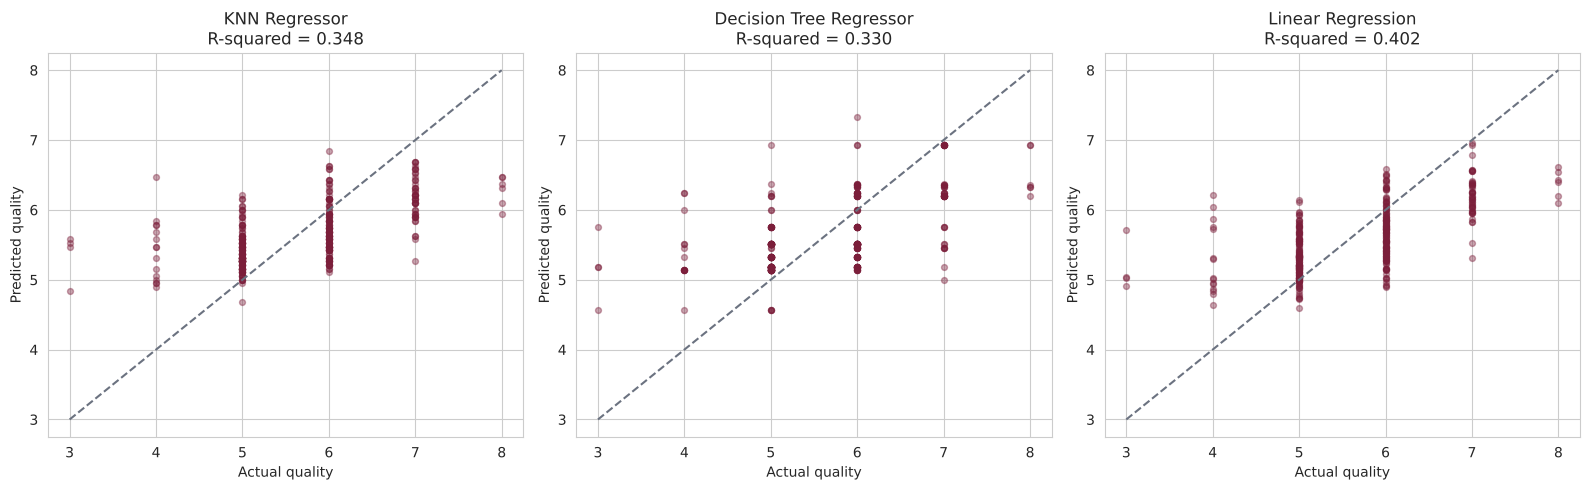

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, p) in zip(axes, reg_pred.items()):
    ax.scatter(s_test, p, alpha=0.4, color=WINE, s=18)
    ax.plot([3, 8], [3, 8], linestyle="--", color=GREY)
    ax.set_xlabel("Actual quality")
    ax.set_ylabel("Predicted quality")
    ax.set_title(f"{name}\nR-squared = {r2_score(s_test, p):.3f}")
plt.tight_layout()
plt.savefig("images/15_regression_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
best_reg_name = reg_results.sort_values("RMSE").index[0]
print("Best regression model:", best_reg_name)
print("RMSE:", round(reg_results.loc[best_reg_name, "RMSE"], 4), "| R-squared:", round(reg_results.loc[best_reg_name, "R-squared"], 4))

# how far off are we on average, in quality points?
errors = np.abs(s_test - reg_pred[best_reg_name])
print("Predictions within 0.5 points :", round((errors <= 0.5).mean() * 100, 1), "%")
print("Predictions within 1.0 point  :", round((errors <= 1.0).mean() * 100, 1), "%")
pd.Series({"within 0.5": round((errors <= 0.5).mean() * 100, 1),
           "within 1.0": round((errors <= 1.0).mean() * 100, 1)}).to_csv("results/regression_within.csv", header=["percent"])

Best regression model: Linear Regression
RMSE: 0.6796 | R-squared: 0.4024
Predictions within 0.5 points : 55.3 %
Predictions within 1.0 point  : 89.4 %


### Predictions for some test wines
A look at the first 20 wines of the test data: the real quality, the group predicted by each classification model, and the score predicted by the best regression model.

In [33]:
group = {0: "Not good", 1: "Good"}
sample_idx = X_test.index[:20]
sample = pd.DataFrame({"Real quality": s_test.loc[sample_idx].values}, index=sample_idx)
sample["Real group"] = y_test.loc[sample_idx].map(group).values
for name, pred in predictions.items():
    sample[name] = pd.Series(pred, index=X_test.index).loc[sample_idx].map(group).values
sample["Predicted score"] = pd.Series(reg_pred[best_reg_name], index=X_test.index).loc[sample_idx].round(2).values
sample = sample.reset_index(drop=True)
sample.index = sample.index + 1
sample.index.name = "Wine no."
sample.to_csv("results/sample_predictions.csv")
sample

,Real quality,Real group,KNN,Naive Bayes,Decision Tree,Logistic Regression,Predicted score
Wine no.,,,,,,,
1,5,Not good,Not good,Good,Good,Good,5.64
2,6,Good,Not good,Not good,Not good,Not good,5.43
3,6,Good,Good,Good,Good,Good,6.42
4,6,Good,Not good,Not good,Good,Good,5.68
5,6,Good,Good,Not good,Good,Good,5.85
6,8,Good,Good,Good,Good,Good,6.61
7,5,Not good,Not good,Not good,Good,Not good,5.35
8,7,Good,Not good,Not good,Good,Good,5.53
9,7,Good,Good,Good,Good,Good,6.20


# Part C - Final model and saving it for the web app

We pick the best classifier and the best regressor, train them once more on **all** the data (more data gives a slightly better model) and save them with `joblib`.
The web app (`app.py`) loads this file.
We also save the outlier limits, because the app must treat typed values the same way as we treated the training data.

In [34]:
final_classifier = clone(models[best_clf_name]).fit(X, y_class)
final_regressor = clone(reg_models[best_reg_name]).fit(X, y_score)

saved = {
    "classifier": final_classifier,
    "regressor": final_regressor,
    "classifier_name": best_clf_name,
    "regressor_name": best_reg_name,
    "feature_names": feature_cols,
    "lower_limits": lower.to_dict(),
    "upper_limits": upper.to_dict(),
    "feature_min": df[feature_cols].min().to_dict(),
    "feature_max": df[feature_cols].max().to_dict(),
    "feature_median": df[feature_cols].median().to_dict(),
    "classifier_accuracy": float(clf_results.loc[best_clf_name, "Accuracy"]),
    "regressor_rmse": float(reg_results.loc[best_reg_name, "RMSE"]),
}
joblib.dump(saved, "models/wine_models.joblib")
pd.Series({"KNN k": best_k, "Decision Tree max_depth": best_depth,
           "KNN Regressor k": best_k_reg, "Decision Tree Regressor max_depth": best_depth_reg}
          ).to_csv("results/best_settings.csv", header=["value"])
print("Saved: models/wine_models.joblib")

Saved: models/wine_models.joblib


### Trying the saved models on two wines

In [35]:
def predict_wine(values):
    # values = dictionary with the 11 measurements
    row = pd.DataFrame([values])[feature_cols]
    row = row.clip(lower=lower, upper=upper, axis=1)       # same outlier handling as training
    prob_good = final_classifier.predict_proba(row)[0, 1]
    score = final_regressor.predict(row)[0]
    return prob_good, score

loaded = joblib.load("models/wine_models.joblib")   # checking that the file loads properly
print("Saved classifier:", loaded["classifier_name"])
print("Saved regressor :", loaded["regressor_name"])
print()

best_wine = df[df["quality"] == 8].iloc[0]
poor_wine = df[df["quality"] == 3].iloc[0]
for label, wine in [("Wine with real quality 8", best_wine), ("Wine with real quality 3", poor_wine)]:
    p, s = predict_wine(wine[feature_cols].to_dict())
    print(f"{label}: chance of being good = {p*100:.1f}%, predicted score = {s:.2f}")

Saved classifier: Logistic Regression
Saved regressor : Linear Regression

Wine with real quality 8: chance of being good = 97.3%, predicted score = 6.72
Wine with real quality 3: chance of being good = 15.7%, predicted score = 5.00


# Conclusion

- The data had no null values but 240 duplicate rows, which we removed. Outliers were capped with the IQR method.
- Alcohol is the column most linked with wine quality. Sulphates, volatile acidity and total sulfur dioxide also matter (both the Decision Tree and Logistic Regression agree on this).
- On the test data **Logistic Regression** gave the best classification result (accuracy about 74%, AUC about 0.83), with Naive Bayes very close. For the score, **Linear Regression** was best (RMSE about 0.68, R-squared about 0.40).
- We trained KNN, Naive Bayes, Decision Tree and Logistic Regression for the good / not good question, and compared them using accuracy, precision, recall, F1-score, AUC and the ROC curve.
- For the exact score we used KNN Regressor, Decision Tree Regressor and Linear Regression and compared RMSE, MAE and R-squared.
- The best models are saved and used in the web app (`app.py`), where anyone can type the 11 measurements of a wine and see if it is predicted to be good.

**Limits of this project:** the data has only red wine and about 1,300 rows, and wine quality depends on taste which cannot be fully measured by a lab test. So the models are helpful but not perfect.